In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('TripLog_DataSet.csv')

In [3]:
df.head()

,VehLat,VehLng,Hour,Minutes,DayOfWeek
0,59.938967,10.647788,0,1,0
1,59.919851,10.743474,0,1,0
2,59.950741,10.794539,0,2,0
3,59.924075,10.741275,0,2,0
4,59.864611,10.800342,0,2,0


In [4]:
features = df[['VehLat', 'VehLng']]

In [5]:
from sklearn.cluster import KMeans

In [6]:
kmean = KMeans(n_clusters = 10, random_state=42)
kmean.fit(features)
df['Cluster'] = kmean.labels_


In [7]:
df.head()

,VehLat,VehLng,Hour,Minutes,DayOfWeek,Cluster
0,59.938967,10.647788,0,1,0,0
1,59.919851,10.743474,0,1,0,0
2,59.950741,10.794539,0,2,0,0
3,59.924075,10.741275,0,2,0,0
4,59.864611,10.800342,0,2,0,0


In [8]:
df['Cluster'].unique()

array([0, 5, 3, 8, 7, 1, 9, 4, 6, 2], dtype=int32)

In [9]:
print(df['Cluster'].value_counts())

Cluster
0    101017
5      8865
7      3349
8      2909
3      2103
2      1261
6       719
1       514
9       477
4       208
Name: count, dtype: int64


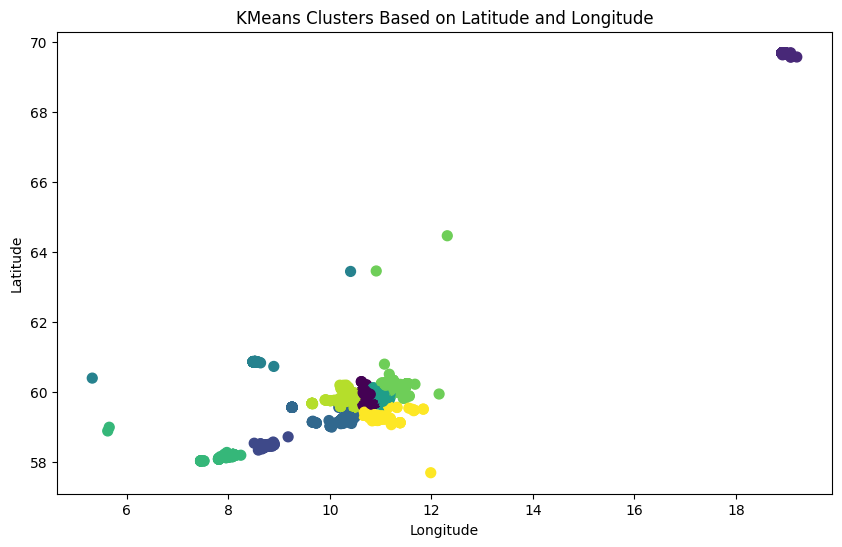

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df['VehLng'], df['VehLat'], c=df['Cluster'], cmap='viridis', s=50)
plt.title("KMeans Clusters Based on Latitude and Longitude")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [11]:
cluster0_data = df[df['Cluster']==0]

X = cluster0_data[['VehLat','VehLng']]

kmean = KMeans(n_clusters = 10, random_state=42)
kmean.fit(X)
cluster0_data['Cluster0'] = kmean.labels_
cluster0_data['Cluster0'] = cluster0_data['Cluster0'] + 10

/tmp/ipython-input-3765200012.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster0_data['Cluster0'] = kmean.labels_
/tmp/ipython-input-3765200012.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster0_data['Cluster0'] = cluster0_data['Cluster0'] + 10


In [12]:
print(cluster0_data['Cluster0'].unique())

[13 17 10 12 11 16 15 18 14 19]


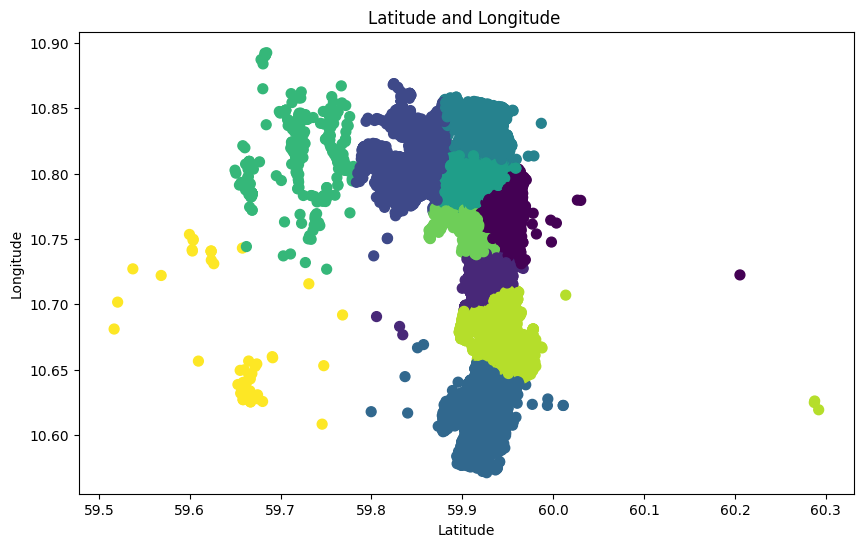

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(cluster0_data['VehLat'], cluster0_data['VehLng'], c=cluster0_data['Cluster0'], cmap='viridis', s=50)
plt.title('Latitude and Longitude ')
plt.xlabel('Latitude')
plt.ylabel('Longitude')

plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X = cluster0_data[['VehLat','VehLng']]
y = cluster0_data['Cluster0']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)

acc = accuracy_score(y_pred,y_test)
print(acc)

0.9972777667788557


In [15]:
# Filter indices where Cluster is 0
cluster_0_indices = df[df['Cluster'] == 0].index

# Assign data from cluster0_data['Cluster0'] to df at the filtered indices
df.loc[cluster_0_indices, 'Cluster'] = cluster0_data['Cluster0'].values


In [16]:
df['Cluster'].unique()

array([13, 17, 10, 12, 11, 16, 15,  5, 18, 14,  3,  8,  7,  1, 19,  9,  4,
        6,  2], dtype=int32)

In [17]:
print(df['Cluster'].value_counts())

Cluster
17    36696
11    31406
10    10054
5      8865
15     7891
18     4368
12     3863
14     3360
7      3349
8      2909
13     2607
3      2103
2      1261
6       719
16      684
1       514
9       477
4       208
19       88
Name: count, dtype: int64


In [18]:
df.head()

,VehLat,VehLng,Hour,Minutes,DayOfWeek,Cluster
0,59.938967,10.647788,0,1,0,13
1,59.919851,10.743474,0,1,0,17
2,59.950741,10.794539,0,2,0,10
3,59.924075,10.741275,0,2,0,17
4,59.864611,10.800342,0,2,0,12


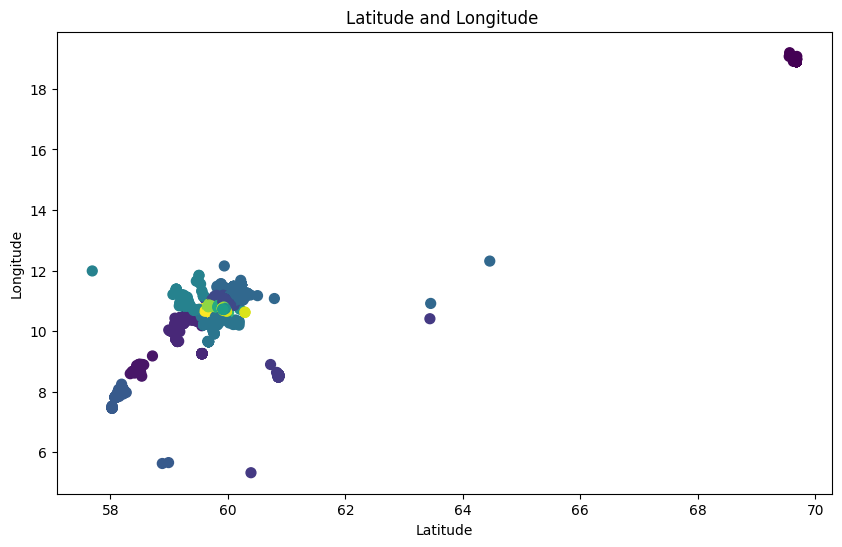

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df['VehLat'], df['VehLng'], c=df['Cluster'], cmap='viridis', s=50)
plt.title('Latitude and Longitude ')
plt.xlabel('Latitude')
plt.ylabel('Longitude')

plt.show()

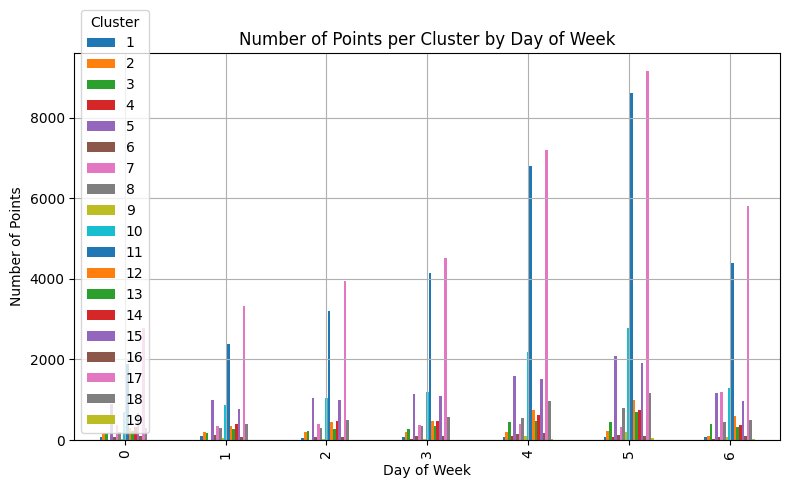

In [20]:
import pandas as pd
import matplotlib.pyplot as plt


# Group by DayOfWeek and Cluster to count number of points
grouped = df.groupby(['DayOfWeek', 'Cluster']).size().unstack(fill_value=0)

# Plot
grouped.plot(kind='bar', figsize=(8, 5))
plt.title('Number of Points per Cluster by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Points')
plt.legend(title='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()


# KNN

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix, f1_score, precision_score, recall_score

10-Fold Cross-Validation Accuracy: 0.9979
10-Fold Cross-Validation Precision: 0.9979
10-Fold Cross-Validation Recall: 0.9979
10-Fold Cross-Validation F1 Score: 0.9979


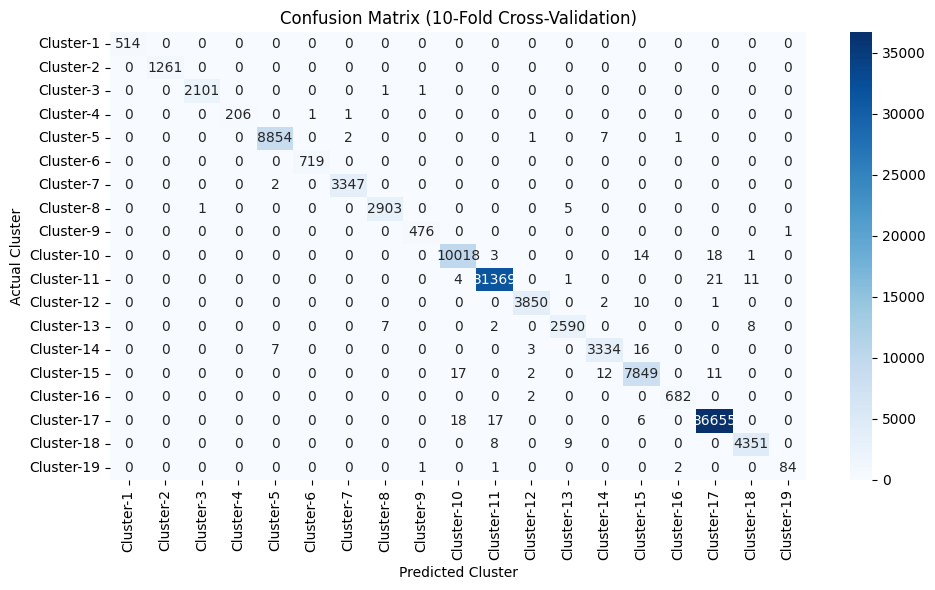

In [22]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Features and labels
X = df[['VehLat', 'VehLng']]
y = df['Cluster']

# Initialize KNN
knn = KNeighborsClassifier(n_neighbors=3)

# 10-fold cross-validation
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Cross-validated scores
accuracy = cross_val_score(knn, X, y, cv=kfold, scoring='accuracy').mean()
precision = cross_val_score(knn, X, y, cv=kfold, scoring='precision_weighted').mean()
recall = cross_val_score(knn, X, y, cv=kfold, scoring='recall_weighted').mean()
f1 = cross_val_score(knn, X, y, cv=kfold, scoring='f1_weighted').mean()

print(f"10-Fold Cross-Validation Accuracy: {accuracy:.4f}")
print(f"10-Fold Cross-Validation Precision: {precision:.4f}")
print(f"10-Fold Cross-Validation Recall: {recall:.4f}")
print(f"10-Fold Cross-Validation F1 Score: {f1:.4f}")

# Cross-validated predictions
y_pred = cross_val_predict(knn, X, y, cv=kfold)

# Confusion matrix
cm = confusion_matrix(y, y_pred)
unique_labels = sorted(list(set(y)))
readable_labels = [f"Cluster-{i}" for i in unique_labels]

plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=readable_labels, yticklabels=readable_labels)

plt.title("Confusion Matrix (10-Fold Cross-Validation)")
plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Cluster")
plt.tight_layout()
plt.show()


# Decision-Tree

10-Fold CV Accuracy: 0.9975
10-Fold CV Precision (weighted): 0.9975
10-Fold CV Recall (weighted): 0.9975
10-Fold CV F1 Score (weighted): 0.9975


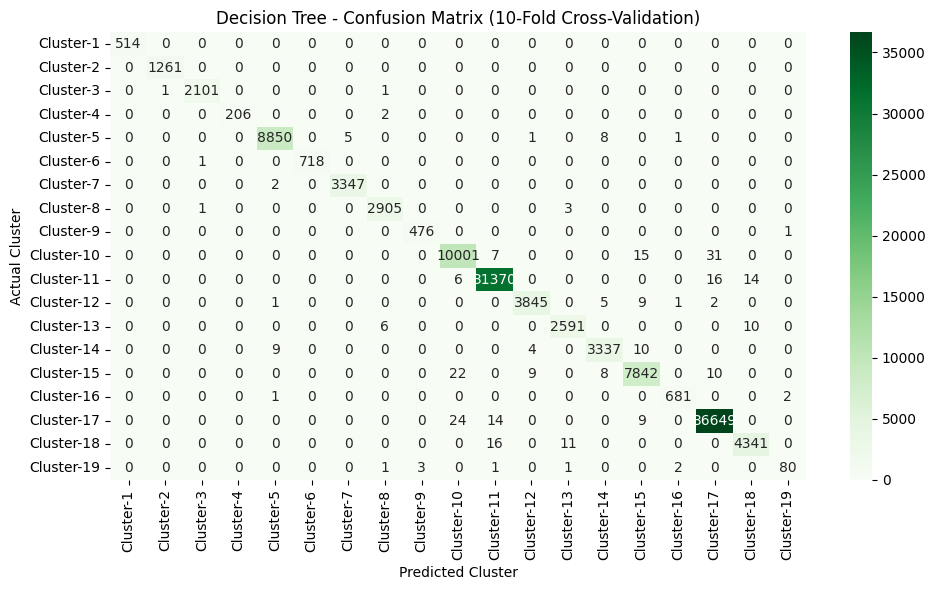

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Features and labels
X = df[['VehLat', 'VehLng']]
y = df['Cluster']

# Initialize Decision Tree
dtree = DecisionTreeClassifier(random_state=42)

# Stratified 10-fold CV
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Cross-validated metrics
accuracy = cross_val_score(dtree, X, y, cv=kfold, scoring='accuracy').mean()
precision = cross_val_score(dtree, X, y, cv=kfold, scoring='precision_weighted').mean()
recall = cross_val_score(dtree, X, y, cv=kfold, scoring='recall_weighted').mean()
f1 = cross_val_score(dtree, X, y, cv=kfold, scoring='f1_weighted').mean()

print(f"10-Fold CV Accuracy: {accuracy:.4f}")
print(f"10-Fold CV Precision (weighted): {precision:.4f}")
print(f"10-Fold CV Recall (weighted): {recall:.4f}")
print(f"10-Fold CV F1 Score (weighted): {f1:.4f}")

# Cross-validated predictions
y_pred = cross_val_predict(dtree, X, y, cv=kfold)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)
labels = sorted(list(set(y)))
readable_labels = [f"Cluster-{i}" for i in labels]

plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=readable_labels, yticklabels=readable_labels)
plt.title("Decision Tree - Confusion Matrix (10-Fold Cross-Validation)")
plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Cluster")
plt.tight_layout()
plt.show()


# Random-Forest

10-Fold CV Accuracy: 0.9983
10-Fold CV Precision (weighted): 0.9983
10-Fold CV Recall (weighted): 0.9983
10-Fold CV F1 Score (weighted): 0.9983


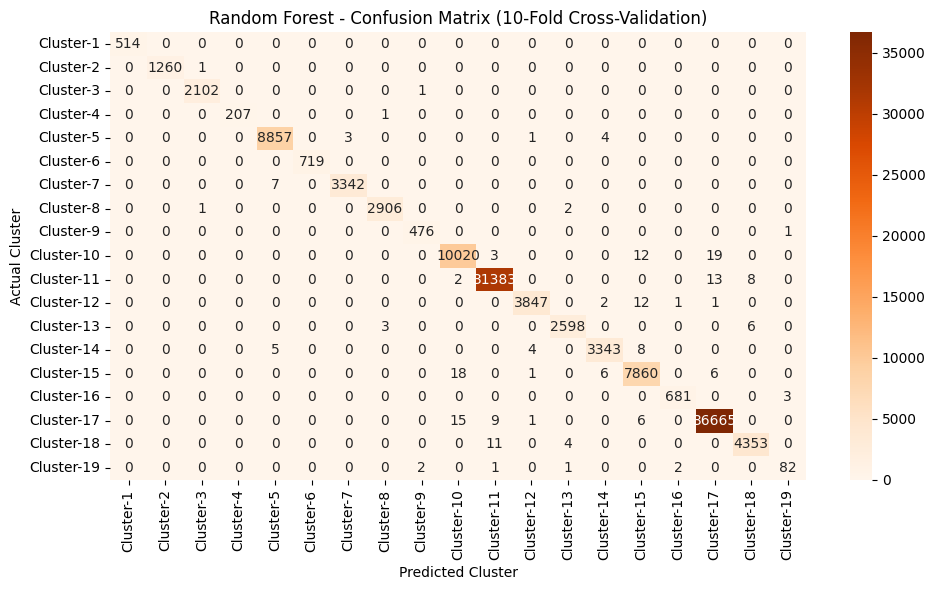

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Feature and target selection
X = df[['VehLat', 'VehLng']]
y = df['Cluster']

# Initialize Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 10-fold Stratified Cross-Validation
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Evaluate using cross_val_score
accuracy = cross_val_score(rf, X, y, cv=kfold, scoring='accuracy').mean()
precision = cross_val_score(rf, X, y, cv=kfold, scoring='precision_weighted').mean()
recall = cross_val_score(rf, X, y, cv=kfold, scoring='recall_weighted').mean()
f1 = cross_val_score(rf, X, y, cv=kfold, scoring='f1_weighted').mean()

print(f"10-Fold CV Accuracy: {accuracy:.4f}")
print(f"10-Fold CV Precision (weighted): {precision:.4f}")
print(f"10-Fold CV Recall (weighted): {recall:.4f}")
print(f"10-Fold CV F1 Score (weighted): {f1:.4f}")

# Predict using cross_val_predict for confusion matrix
y_pred = cross_val_predict(rf, X, y, cv=kfold)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)
labels = sorted(list(set(y)))
readable_labels = [f"Cluster-{i}" for i in labels]

plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=readable_labels, yticklabels=readable_labels)
plt.title("Random Forest - Confusion Matrix (10-Fold Cross-Validation)")
plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Cluster")
plt.tight_layout()
plt.show()


In [27]:
import pandas as pd


df['SubCluster'] = None

# Loop over each main cluster
for cluster_id in df['Cluster'].unique():
    # Filter data for each main cluster
    cluster_data = df[df['Cluster'] == cluster_id]

    # Loop over each day of the week (0 to 6)
    for day in range(7):
        # Create subcluster label based on the day of the week within each main cluster
        df.loc[(df['Cluster'] == cluster_id) & (df['DayOfWeek'] == day), 'SubCluster'] = day

# Check the results
df


,VehLat,VehLng,Hour,Minutes,DayOfWeek,Cluster,SubCluster
0,59.938967,10.647788,0,1,0,13,0
1,59.919851,10.743474,0,1,0,17,0
2,59.950741,10.794539,0,2,0,10,0
3,59.924075,10.741275,0,2,0,17,0
4,59.864611,10.800342,0,2,0,12,0
...,...,...,...,...,...,...,...
121417,59.929234,10.711216,8,20,2,11,2
121418,60.194886,11.098768,8,22,2,7,2
121419,59.910958,10.728104,8,23,2,11,2
121420,59.957239,10.744013,8,24,2,10,2


In [ ]:
df.to_csv('TripLog_Clustered.csv',index=False)

In [ ]:
df = pd.read_csv('TripLog_Clustered.csv')
df.head()

,VehLat,VehLng,Hour,Minutes,DayOfWeek,Cluster,SubCluster
0,59.938967,10.647788,0,1,0,13,0
1,59.919851,10.743474,0,1,0,17,0
2,59.950741,10.794539,0,2,0,10,0
3,59.924075,10.741275,0,2,0,17,0
4,59.864611,10.800342,0,2,0,12,0


In [28]:
day_counts = df.groupby(['Cluster', 'SubCluster']).size().reset_index(name='Points')

# Display the counts for each day within each cluster in the specified format
for cluster_id in df['Cluster'].unique():
    print(f"Cluster {cluster_id}:")
    for day in range(7):
        day_count = day_counts[(day_counts['Cluster'] == cluster_id) & (day_counts['SubCluster'] == day)]
        points = day_count['Points'].values[0] if not day_count.empty else 0
        print(f"  Day {day} points = {points}")

Cluster 13:
  Day 0 points = 220
  Day 1 points = 268
  Day 2 points = 280
  Day 3 points = 334
  Day 4 points = 478
  Day 5 points = 696
  Day 6 points = 331
Cluster 17:
  Day 0 points = 2777
  Day 1 points = 3314
  Day 2 points = 3950
  Day 3 points = 4516
  Day 4 points = 7192
  Day 5 points = 9144
  Day 6 points = 5803
Cluster 10:
  Day 0 points = 695
  Day 1 points = 876
  Day 2 points = 1031
  Day 3 points = 1193
  Day 4 points = 2181
  Day 5 points = 2781
  Day 6 points = 1297
Cluster 12:
  Day 0 points = 288
  Day 1 points = 354
  Day 2 points = 447
  Day 3 points = 461
  Day 4 points = 750
  Day 5 points = 983
  Day 6 points = 580
Cluster 11:
  Day 0 points = 1887
  Day 1 points = 2387
  Day 2 points = 3202
  Day 3 points = 4137
  Day 4 points = 6790
  Day 5 points = 8602
  Day 6 points = 4401
Cluster 16:
  Day 0 points = 88
  Day 1 points = 75
  Day 2 points = 65
  Day 3 points = 101
  Day 4 points = 161
  Day 5 points = 102
  Day 6 points = 92
Cluster 15:
  Day 0 points = 67

In [29]:
pip install folium

In [30]:
import folium
from folium.plugins import MarkerCluster

# Create a base map centered around the average latitude and longitude
average_lat = df['VehLat'].mean()
average_lng = df['VehLng'].mean()
map_center = [average_lat,average_lng]
m = folium.Map(location=map_center, zoom_start=12)

# Create a MarkerCluster for better visualization of points
marker_cluster = MarkerCluster().add_to(m)

# Loop through each unique cluster and subcluster to add them to the map
for cluster_id in df['Cluster'].unique():
    cluster_data = df[df['Cluster'] == cluster_id]

    # Add a circle marker for the main cluster
    cluster_location = cluster_data[['VehLat', 'VehLng']].mean()  # Get the mean location for the cluster
    folium.Marker(
        location=(cluster_location['VehLat'], cluster_location['VehLng']),
        popup=f'Cluster {cluster_id}',
        icon=folium.Icon(color='red')
    ).add_to(marker_cluster)

    # Loop through each subcluster and add a marker summarizing it
    for day in range(7):
        subcluster_data = cluster_data[cluster_data['DayOfWeek'] == day]

        if not subcluster_data.empty:
            # Calculate mean location for the subcluster for better visualization
            subcluster_location = subcluster_data[['VehLat', 'VehLng']].mean()
            num_points = subcluster_data.shape[0]  # Get the number of points in the subcluster
            subcluster_name = f'Subcluster (Cluster {cluster_id}, Day {day})'

            folium.Marker(
                location=(subcluster_location['VehLat'], subcluster_location['VehLng']),
                popup=f'{subcluster_name}<br>Points: {num_points}',  # Show subcluster name and number of points
                icon=folium.Icon(color='blue')
            ).add_to(marker_cluster)

# Add layer control to the map
folium.LayerControl().add_to(m)

# Save the map to an HTML file
m.save('clusters_map.html')
m


In [31]:
pip install haversine

In [35]:
from datetime import timedelta
import pandas as pd
from haversine import haversine
import folium
import time

DAY_NAMES = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}

##########################################################################################################################################

def predict_nearest_subclusters(latitude, longitude, hour, minute, day_of_week, num_neighbors=3):
    start_time = time.time()

    distances = []
    for index, row in df.iterrows():
        if row['Hour'] == hour and row['Minutes'] == minute and row['DayOfWeek'] == day_of_week:
            distance = haversine((latitude, longitude), (row['VehLat'], row['VehLng']))
            distances.append((row['Cluster'], row['SubCluster'], row['VehLat'], row['VehLng'], distance))

    distances.sort(key=lambda x: x[4])

    unique_clusters = {}
    nearest_subclusters = []
    for cluster, subcluster, lat, lng, distance in distances:
        if cluster not in unique_clusters and len(nearest_subclusters) < num_neighbors:
            unique_clusters[cluster] = True
            nearest_subclusters.append((subcluster, lat, lng, distance, cluster))

    end_time = time.time()
    print(f"\n⏱️ predict_nearest_subclusters() executed in {end_time - start_time:.4f} seconds (O(n log n))")
    return nearest_subclusters

##########################################################################################################################################

def calculate_points_for_selected_subclusters(df, nearest_subclusters, day_of_week, hour, minute, time_window):
    start_time = time.time()

    points_per_subcluster_day_time = {}
    target_time = timedelta(hours=hour, minutes=minute)
    start_time_window = target_time - timedelta(minutes=time_window)
    end_time_window = target_time + timedelta(minutes=time_window)

    relevant_clusters = set(sub[4] for sub in nearest_subclusters)

    for index, row in df.iterrows():
        row_time = timedelta(hours=row['Hour'], minutes=row['Minutes'])
        if row['DayOfWeek'] == day_of_week and start_time_window <= row_time <= end_time_window and row['Cluster'] in relevant_clusters:
            key = (row['Cluster'], day_of_week)
            points_per_subcluster_day_time[key] = points_per_subcluster_day_time.get(key, 0) + 1

    end_time = time.time()
    print(f"⏱️ calculate_points_for_selected_subclusters() executed in {end_time - start_time:.4f} seconds (O(n))")
    return points_per_subcluster_day_time

##########################################################################################################################################

def create_map(nearest_subclusters, center_lat, center_lng, points_per_subcluster_day_time, day_of_week, hour, minute, time_window):
    start_time = time.time()

    m = folium.Map(location=[center_lat, center_lng], zoom_start=14)
    folium.Marker(location=[center_lat, center_lng], popup='Driver Location', icon=folium.Icon(color='red')).add_to(m)

    for subcluster in nearest_subclusters:
        subcluster_name, lat, lng, distance, cluster_name = subcluster
        key = (cluster_name, day_of_week)
        total_points = points_per_subcluster_day_time.get(key, 0)

        if total_points > 0:
            day_name = DAY_NAMES.get(day_of_week, 'Unknown')
            folium.Marker(
                location=[lat, lng],
                popup=(f'Cluster: {cluster_name}, '
                       f'SubCluster: {day_name}, '
                       f'Distance: {distance:.2f} km, '
                       f'Pickups: {total_points}'),
                icon=folium.Icon(color='blue')
            ).add_to(m)

    end_time = time.time()
    print(f"⏱️ create_map() executed in {end_time - start_time:.4f} seconds (O(1))")
    return m

##########################################################################################################################################

# Input
latitude = 59.909851
longitude = 10.743474
hour = 14
minute = 30
day_of_week = 1  # Tuesday
time_window = 10

nearest_subclusters = predict_nearest_subclusters(latitude, longitude, hour, minute, day_of_week)
points_per_subcluster_day_time = calculate_points_for_selected_subclusters(df, nearest_subclusters, day_of_week, hour, minute, time_window)
folium_map = create_map(nearest_subclusters, latitude, longitude, points_per_subcluster_day_time, day_of_week, hour, minute, time_window)

folium_map.save("nearest_subclusters_map.html")
folium_map



⏱️ predict_nearest_subclusters() executed in 6.0706 seconds (O(n log n))
⏱️ calculate_points_for_selected_subclusters() executed in 5.5484 seconds (O(n))
⏱️ create_map() executed in 0.0067 seconds (O(1))


In [34]:
from datetime import timedelta
import pandas as pd
from haversine import haversine
import folium
import time

DAY_NAMES = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}

##########################################################################################################################################

def predict_nearest_subclusters(df, latitude, longitude, hour, minute, day_of_week, num_neighbors=3, time_window=10):
    """
    Find 3 nearest subclusters for the given day and driver location,
    and count number of pickups within ±time_window minutes.
    """

    start_time = time.time()  # start timing

    # Filter by day
    day_df = df[df["DayOfWeek"] == day_of_week]

    # Compute average coordinates per subcluster (centroid)
    subcluster_centroids = (
        day_df.groupby(["Cluster", "SubCluster"])[["VehLat", "VehLng"]]
        .mean()
        .reset_index()
    )

    # Calculate distance from driver to each subcluster centroid
    subcluster_centroids["Distance"] = subcluster_centroids.apply(
        lambda r: haversine((latitude, longitude), (r["VehLat"], r["VehLng"])), axis=1
    )

    # Pick top N nearest subclusters
    nearest_subclusters = subcluster_centroids.nsmallest(num_neighbors, "Distance")

    # Create dictionary to store points count
    points_info = {}

    # Calculate time window range
    driver_time = timedelta(hours=hour, minutes=minute)
    time_window_delta = timedelta(minutes=time_window)

    # For each nearest subcluster, count points within ±time_window
    for _, row in nearest_subclusters.iterrows():
        cluster = row["Cluster"]
        subcluster = row["SubCluster"]
        sub_df = day_df[(day_df["Cluster"] == cluster) & (day_df["SubCluster"] == subcluster)]

        count = 0
        for _, record in sub_df.iterrows():
            record_time = timedelta(hours=record["Hour"], minutes=record["Minutes"])
            if abs(record_time - driver_time) <= time_window_delta:
                count += 1

        points_info[(cluster, subcluster)] = count

    end_time = time.time()
    execution_time = end_time - start_time
    print(f"\n⏱️ Time to find nearest subclusters and counts: {execution_time:.4f} seconds\n")

    return nearest_subclusters, points_info

##########################################################################################################################################

def create_map(nearest_subclusters, points_info, center_lat, center_lng, day_of_week):
    m = folium.Map(location=[center_lat, center_lng], zoom_start=13)

    # Add driver marker
    folium.Marker(
        [center_lat, center_lng],
        popup="Driver Location",
        icon=folium.Icon(color="red"),
    ).add_to(m)

    # Add subcluster markers
    for _, row in nearest_subclusters.iterrows():
        cluster = row["Cluster"]
        subcluster = row["SubCluster"]
        lat = row["VehLat"]
        lng = row["VehLng"]
        distance = row["Distance"]
        pickups = points_info.get((cluster, subcluster), 0)

        folium.Marker(
            [lat, lng],
            popup=(f"Cluster: {cluster}<br>"
                   f"SubCluster: {subcluster}<br>"
                   f"Day: {DAY_NAMES[day_of_week]}<br>"
                   f"Distance: {distance:.2f} km<br>"
                   f"Pickups (±10 min): {pickups}"),
            icon=folium.Icon(color="blue"),
        ).add_to(m)

    return m

##########################################################################################################################################

# Example Input
latitude = 59.909851
longitude = 10.743474
hour = 14
minute = 30
day_of_week = 1  # Tuesday
time_window = 10

# Run main pipeline
nearest_subclusters, points_info = predict_nearest_subclusters(df, latitude, longitude, hour, minute, day_of_week, num_neighbors=3, time_window=time_window)

folium_map = create_map(nearest_subclusters, points_info, latitude, longitude, day_of_week)
folium_map.save("nearest_subclusters_map.html")

print("✅ Map created and saved as 'nearest_subclusters_map.html'")
folium_map



⏱️ Time to find nearest subclusters and counts: 0.4733 seconds

✅ Map created and saved as 'nearest_subclusters_map.html'


In [33]:
from datetime import timedelta
import pandas as pd

target_cluster = 17
target_subcluster = 1
start_time = timedelta(hours=14, minutes=20)
end_time = timedelta(hours=14, minutes=40)

filtered_points = df[
    (df['Cluster'] == target_cluster) &
    (df['SubCluster'] == target_subcluster) &
    (df.apply(lambda row: start_time <= timedelta(hours=row['Hour'], minutes=row['Minutes']) <= end_time, axis=1))
]

print("Filtered Points:\n",filtered_points)
print("Total Number of Points:",len(filtered_points))


Filtered Points:
            VehLat     VehLng  Hour  Minutes  DayOfWeek  Cluster SubCluster
735     59.907481  10.755972    14       31          1       17          1
5165    59.912158  10.751515    14       21          1       17          1
8347    59.913454  10.754445    14       23          1       17          1
17140   59.912337  10.753696    14       25          1       17          1
25374   59.912354  10.749024    14       34          1       17          1
28126   59.912126  10.753058    14       20          1       17          1
28127   59.913159  10.761399    14       21          1       17          1
28128   59.909866  10.752896    14       25          1       17          1
31034   59.910666  10.749620    14       27          1       17          1
33594   59.908993  10.750428    14       28          1       17          1
39029   59.912299  10.748988    14       39          1       17          1
42348   59.907163  10.756856    14       27          1       17          1
45968  